<a href="https://colab.research.google.com/github/theMorana/HSE/blob/main/Deep_Learning/Homework_notebooks/RNN_homework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Классификация текстов с помощью RNN (PyTorch)

- загрузка и визуализация данных;
- токенизация и словарь;
- RNN-классификатор;
- обучение, кривые, матрица ошибок;
- задания с плейсхолдерами для изменения гиперпараметров.

## 1. Окружение

In [1]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib

In [2]:
import re
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

Using device: cuda


## 2. Загрузка данных

In [4]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nПример:", dataset['train'][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Пример: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [5]:
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['test']['label'],
    dataset['test']['text']
))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

Обучающих примеров: 120000
Тестовых примеров: 7600

Распределение меток: Counter({2: 30000, 3: 30000, 1: 30000, 0: 30000})


## 3. Визуализация данных

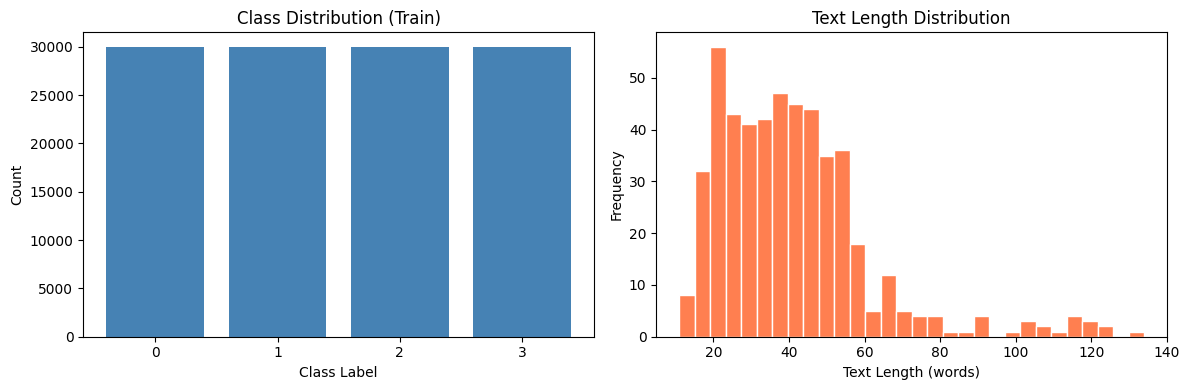

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [label for label, _ in train_data]
label_counts = Counter(labels)

axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

In [7]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label {label}] {text[:150]}...")


=== Примеры ===
[Label 2] Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....
[Label 2] Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and ...
[Label 2] Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expecte...


## 4. Токенизация и словарь

In [8]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [9]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [10]:
# ============================================
# Задание 1: параметры построения словаря

# MIN_FREQ = 5 --> Размер словаря = 27831
# MIN_FREQ = 10  --> Размер словаря = 19638
# Редкие слова мешают в случае, когда не релевантны и являются шумом, и полезны, когда являются искомыми (термины, например)
# ============================================
MIN_FREQ = 2

# Сначала строим словарь только из реальных токенов
vocab = build_vocab_from_iterator(
    yield_tokens(train_data),
    min_freq=MIN_FREQ
)

# Добавляем специальные токены вручную

# Устанавливаем токен по умолчанию для неизвестных слов
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

print(f"Размер словаря: {len(vocab)}")
print(f"PAD_IDX = {PAD_IDX}, UNK_IDX = {UNK_IDX}")

Размер словаря: 44138
PAD_IDX = 0, UNK_IDX = 1


## 5. Предобработка и Dataset

In [11]:
# ============================================
# Задание 2: длина последовательности (обрезка)
# Попробуйте MAX_LEN = 128, 256, 512. Как меняются скорость обучения и точность?
# Почему у RNN может не быть выигрыша от очень длинных последовательностей?
# ============================================
MAX_LEN = 256  # <-- меняйте здесь

# ответ на вопросы:

# 128 к 256: точность часто растёт — модель видит больше контекста.
# 256 к 512: точность либо выходит на плато, либо падает - эффект забывания и переобучения на шумных дальних зависимостях.
# более 512: часто деградация — градиенты затухают/взрываются, модель не может эффективно использовать дальний контекст.
# У RNN не может быть выигрыша от очень длинных последовательностей из-за ограниченной памяти скрытого состояния и вычислительной стоимости.

In [12]:
def text_pipeline(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]

    # На случай пустого текста
    if len(ids) == 0:
        ids = [UNK_IDX]

    return ids


def label_pipeline(label):
    return label

In [13]:
class AGNewsDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [14]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [15]:
train_dataset = AGNewsDataset(
    train_data,
    text_pipeline,
    label_pipeline
)

test_dataset = AGNewsDataset(
    test_data,
    text_pipeline,
    label_pipeline
)

## 6. DataLoader

In [16]:
# ============================================
# Задание 3: размер батча
# Попробуйте BATCH_SIZE = 32, 64, 128. Как это влияет на стабильность обучения и скорость?
# Документация: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# ============================================
BATCH_SIZE = 64  # <-- меняйте здесь

# чем меньше размер батча, тем медленнее скорость, ниже стабильность, но лучше обобщение и требуется меньше памяти. чем выше - наоборот

In [17]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(
    f"Количество батчей в обучении: "
    f"{len(train_loader)}"
)

Количество батчей в обучении: 1875


## 7. RNN-модель

In [18]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

In [19]:
# ============================================
# Задание 4: гиперпараметры модели
# Попробуйте разные комбинации и посмотрите на точность на валидации:
#   EMBED_DIM: 64, 128, 256
#   HIDDEN_DIM: 64, 128, 256
#   NUM_LAYERS: 1, 2
#   BIDIRECTIONAL: True / False
# Как размер скрытого состояния связан с числом параметров и качеством? - скрытое состояние находится в квадратичной зависимости от количества параметров
# ============================================
EMBED_DIM = 128       # <-- меняйте здесь
HIDDEN_DIM = 128      # <-- меняйте здесь
NUM_LAYERS = 1        # <-- меняйте здесь
BIDIRECTIONAL = True # <-- меняйте здесь (True/False)
DROPOUT = 0.2

In [20]:
model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

RNNClassifier(
  (embedding): Embedding(44138, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=4, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 5,716,740


## 8. Обучение и проверка

In [21]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [22]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [23]:
# ============================================
# Задание 5: параметры оптимизатора
# Попробуйте LEARNING_RATE = 1e-3, 5e-4, 1e-4.
# Как скорость обучения влияет на сходимость и стабильность?
# Документация: https://pytorch.org/docs/stable/optim.html#torch.optim.Adam
# ============================================
LEARNING_RATE = 1e-3  # <-- меняйте здесь
NUM_EPOCHS = 5        # <-- меняйте здесь

# 1e-3 - верхняя граница для RNN, выше почти всегда расходимость.
# 5e-4 - тоже оптимально для большинства задач с LSTM/GRU.
# 1e-4 - для тонкой настройки, но требует в 2–3 раза больше эпох.

In [24]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 99.23it/s] 


Epoch 1/5 | Train Loss: 0.7089 | Train Acc: 0.7219 | Val Loss: 0.4443 | Val Acc: 0.8495


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 104.07it/s]


Epoch 2/5 | Train Loss: 0.4028 | Train Acc: 0.8620 | Val Loss: 0.3894 | Val Acc: 0.8726


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 104.68it/s]


Epoch 3/5 | Train Loss: 0.3327 | Train Acc: 0.8891 | Val Loss: 0.3264 | Val Acc: 0.8914


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 95.10it/s] 


Epoch 4/5 | Train Loss: 0.2897 | Train Acc: 0.9025 | Val Loss: 0.3279 | Val Acc: 0.8937


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 99.66it/s] 

Epoch 5/5 | Train Loss: 0.2625 | Train Acc: 0.9129 | Val Loss: 0.2941 | Val Acc: 0.9026


## 9. Кривые обучения

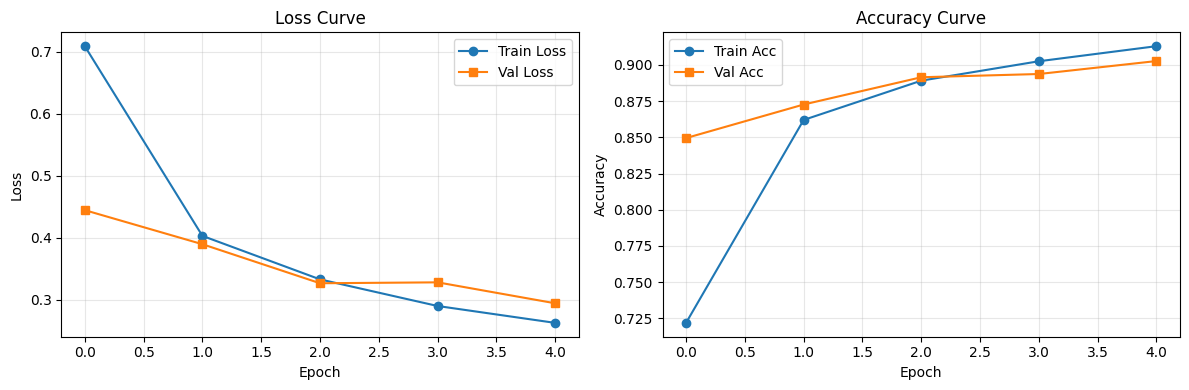

In [25]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Матрица ошибок и classification report

In [26]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test loss: {val_loss:.4f}")
print(f"Test accuracy: {val_acc:.4f}")

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 101.95it/s]

Test loss: 0.2941
Test accuracy: 0.9026


In [27]:
class_names = [
    'World',
    'Sports',
    'Business',
    'Sci/Tech'
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

       World       0.90      0.91      0.90      1900
      Sports       0.95      0.96      0.95      1900
    Business       0.88      0.86      0.87      1900
    Sci/Tech       0.89      0.88      0.88      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600



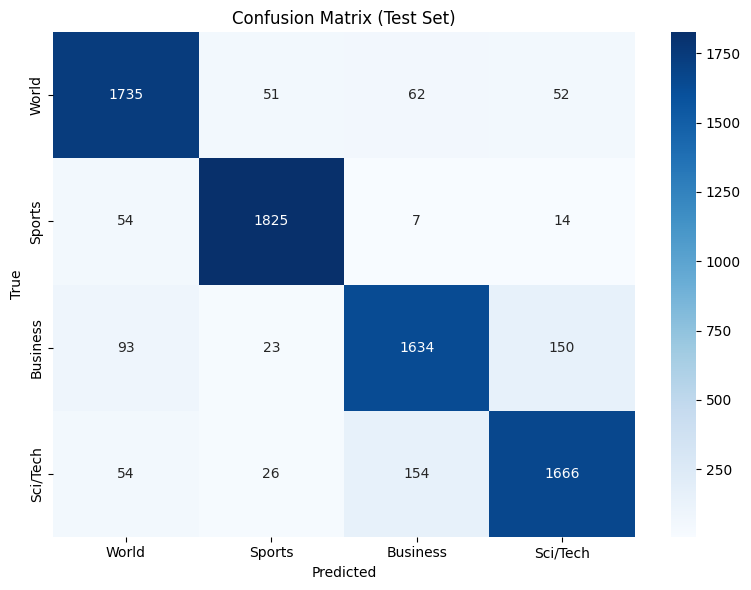

In [28]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

## 11. Контрольные вопросы для студентов

1. **Почему в этом ноутбуке используется `pack_padded_sequence`?**  
   Что произойдёт, если убрать `pack_padded_sequence` и просто подать `padded` тензор в RNN?

2. **Как `min_freq` влияет на размер словаря и на количество параметров embedding-слоя?**  
   Оцените, как меняется число обучаемых параметров при `MIN_FREQ = 2` и `MIN_FREQ = 10`.

3. **Что означает `lengths.cpu()` в вызове `pack_padded_sequence`?**  
   Почему длины должны быть на CPU, а не на GPU?

4. **Почему при `BIDIRECTIONAL = True` используется `torch.cat([hidden[-2], hidden[-1]], dim=1)`?**  
   Что хранится в `hidden[-2]` и `hidden[-1]`?

5. **Как размер `HIDDEN_DIM` связан с числом параметров RNN?**  
   Выведите формулу для числа параметров `nn.RNN` (без bias и с bias).

6. **Почему `clip_grad_norm_` особенно важен для RNN?**  
   С каким явлением он борется?

7. **Что произойдёт, если `MAX_LEN` сделать очень большим (например, 2048)?**  
   Как это повлияет на время обучения, память и качество?

8. **Почему `padding_idx=PAD_IDX` важен в `nn.Embedding`?**  
   Что произойдёт, если его не указывать?

9. **Как интерпретировать матрицу ошибок?**  
   Какие классы чаще всего путаются и почему?

10. **Почему accuracy может быть не лучшей метрикой для этой задачи?**  
    Посмотрите на `classification_report` и объясните, какие метрики здесь информативнее.

## 12. Домашнее задание

### Часть A. Эксперименты с гиперпараметрами

Проведите **минимум 5 экспериментов**, меняя по одному гиперпараметру за раз:

1. `MIN_FREQ`: 2, 5, 10
2. `MAX_LEN`: 128, 256, 512
3. `BATCH_SIZE`: 32, 64, 128
4. `EMBED_DIM` / `HIDDEN_DIM`: (64, 64), (128, 128), (256, 256)
5. `NUM_LAYERS`: 1, 2
6. `BIDIRECTIONAL`: True / False
7. `LEARNING_RATE`: 1e-3, 5e-4, 1e-4

Для каждого эксперимента зафиксируйте:
- размер словаря;
- число параметров модели;
- время одной эпохи;
- `val_loss` и `val_acc` после 3–5 эпох.

Сведите результаты в таблицу и постройте графики зависимости `val_acc` от каждого гиперпараметра.

### Часть B. Анализ ошибок

1. Найдите **10 примеров**, на которых модель ошибается.
2. Для каждого примера укажите: истинный класс, предсказанный класс, текст (можно первые 200 символов).
3. Предложите **гипотезы**, почему модель ошибается (короткий текст, смешанная тематика, редкие слова и т.д.).
4. Предложите **2–3 идеи**, как улучшить модель именно на этих примерах.

### Часть C. Улучшение архитектуры

Замените `nn.RNN` на одну из архитектур:
- `nn.LSTM`
- `nn.GRU`
- двунаправленный LSTM/GRU

Сравните с базовой RNN по тем же метрикам. Объясните, почему LSTM/GRU часто работают лучше на длинных последовательностях.

### Часть D. Мини-исследование

Проверьте гипотезу: **«чем длиннее текст, тем лучше модель его классифицирует»**.

1. Разбейте тестовые примеры на группы по длине (например, 0–50, 51–100, 101–200, 200+ слов).
2. Посчитайте accuracy для каждой группы.
3. Постройте график зависимости accuracy от длины.
4. Сформулируйте вывод: подтверждается ли гипотеза?

### Формат сдачи

- Ноутбук `.ipynb` со всеми выполненными ячейками.
- Краткий отчёт (markdown внутри ноутбука): таблица экспериментов, графики, анализ ошибок, выводы.
- Ссылка на GitHub / Colab или сам файл.

#Задание 1

Все эксперименты были объединены в одну большую функцию, потребовались изменения исходного кода.

In [29]:
def make_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()
    for tokens in iterator:
        counter.update(tokens)

    vocab = {'<pad>': 0, '<unk>': 1}
    frequent_tokens = [
        t for t, f in counter.items()
        if f >= min_freq and t not in ('<pad>', '<unk>')
    ]
    frequent_tokens.sort(key=lambda t: (-counter[t], t))
    vocab.update({t: i for i, t in enumerate(frequent_tokens, start=2)})
    return vocab


def build_vocab(train_data, min_freq):
    return make_vocab_from_iterator(
        yield_tokens(train_data),
        min_freq=min_freq
    )


def make_text_pipeline(vocab, max_len):
    """Return function text_pipeline for paticular dictionary & max_len."""
    def text_pipeline(text):
        tokens = tokenizer(text)
        ids = [vocab.get(token, vocab['<unk>']) for token in tokens]

        if len(ids) > max_len:
            ids = ids[:max_len]

        if len(ids) == 0:
            ids = [vocab['<unk>']]

        return ids

    return text_pipeline


def make_collate_fn(pad_idx):
    """return collate_fn with necessary padding_value."""
    def collate_batch(batch):
        text_list, label_list = zip(*batch)

        lengths = torch.tensor(
            [len(text) for text in text_list],
            dtype=torch.long
        )

        padded = pad_sequence(
            text_list,
            batch_first=True,
            padding_value=pad_idx
        )

        labels = torch.stack(label_list)

        return padded, lengths, labels

    return collate_batch


def make_dataloaders(train_data, test_data, vocab, max_len, batch_size):
    """Create train_loader & test_loader for set parameters"""
    text_pipeline = make_text_pipeline(vocab, max_len)
    collate_fn = make_collate_fn(vocab['<pad>'])

    train_dataset = AGNewsDataset(train_data, text_pipeline, label_pipeline)
    test_dataset  = AGNewsDataset(test_data,  text_pipeline, label_pipeline)

    pin = torch.cuda.is_available()

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_fn,
        num_workers=2,
        pin_memory=pin
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=2,
        pin_memory=pin
    )

    return train_loader, test_loader

class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        pad_idx,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=pad_idx
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = hidden_dim * 2 if bidirectional else hidden_dim

        self.fc = nn.Linear(rnn_output_dim, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            last_hidden = hidden[-1]

        return self.fc(self.dropout(last_hidden))

In [30]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in loader:
        texts   = texts.to(device)
        lengths = lengths.to(device)
        labels  = labels.to(device)

        optimizer.zero_grad()
        logits = model(texts, lengths)
        loss = criterion(logits, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        preds = logits.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)
        total_correct += (preds == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for texts, lengths, labels in loader:
            texts   = texts.to(device)
            lengths = lengths.to(device)
            labels  = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)
            preds = logits.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)
            total_correct += (preds == labels).sum().item()
            total_samples += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [31]:
import time


def run_experiment(
    name,
    train_data,
    test_data,
    min_freq=5,
    max_len=256,
    batch_size=64,
    embed_dim=128,
    hidden_dim=128,
    num_layers=1,
    bidirectional=True,
    dropout=0.2,
    learning_rate=1e-3,
    num_epochs=5,
    num_classes=4,
    seed=42,
    verbose=True
):
    """Run one experiment and retutn dictionary with results"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # dictionary
    vocab = build_vocab(train_data, min_freq=min_freq)

    # loader
    train_loader, test_loader = make_dataloaders(
        train_data, test_data, vocab,
        max_len=max_len, batch_size=batch_size
    )

    # model
    model = RNNClassifier(
        vocab_size=len(vocab),
        embed_dim=embed_dim,
        hidden_dim=hidden_dim,
        num_classes=num_classes,
        pad_idx=vocab['<pad>'],
        num_layers=num_layers,
        dropout=dropout,
        bidirectional=bidirectional
    ).to(device)

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # learning
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    epoch_times = []

    for epoch in range(num_epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        epoch_time = time.time() - t0

        va_loss, va_acc, _, _ = evaluate(model, test_loader, criterion, device)

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        epoch_times.append(epoch_time)

        if verbose:
            print(
                f"[{name}] Epoch {epoch+1}/{num_epochs} | "
                f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.4f} | "
                f"Val Loss: {va_loss:.4f} | Val Acc: {va_acc:.4f} | "
                f"Time: {epoch_time:.1f}s"
            )

    result = {
        'name': name,
        'min_freq': min_freq,
        'max_len': max_len,
        'batch_size': batch_size,
        'embed_dim': embed_dim,
        'hidden_dim': hidden_dim,
        'num_layers': num_layers,
        'bidirectional': bidirectional,
        'learning_rate': learning_rate,
        'vocab_size': len(vocab),
        'n_params': n_params,
        'avg_epoch_time': float(np.mean(epoch_times)),
        'final_val_loss': history['val_loss'][-1],
        'final_val_acc': history['val_acc'][-1],
        'history': history,
    }
    return result

In [ ]:
# Базовая конфигурация (baseline)

BASE_CONFIG = dict(
    min_freq=5,
    max_len=256,
    batch_size=64,
    embed_dim=128,
    hidden_dim=128,
    num_layers=1,
    bidirectional=True,
    dropout=0.2,
    learning_rate=1e-3,
)

NUM_EPOCHS = 5
NUM_CLASSES = 4


# EXPERIMENTS

def _with(base, **overrides):
    """Возвращает копию base с переопределёнными полями """
    cfg = dict(base)
    cfg.update(overrides)
    return cfg

EXPERIMENTS = [
    # ── 1. MIN_FREQ ─────────────────────────────────────────
    dict(name="E1_min_freq=2",  **_with(BASE_CONFIG, min_freq=2)),
    dict(name="E1b_min_freq=10", **_with(BASE_CONFIG, min_freq=10)),

    # ── 2. MAX_LEN ──────────────────────────────────────────
    dict(name="E2_max_len=128", **_with(BASE_CONFIG, max_len=128)),
    dict(name="E2b_max_len=512", **_with(BASE_CONFIG, max_len=512)),

    # ── 3. BATCH_SIZE ───────────────────────────────────────
    dict(name="E3_batch_size=32",  **_with(BASE_CONFIG, batch_size=32)),
    dict(name="E3b_batch_size=128", **_with(BASE_CONFIG, batch_size=128)),

    # ── 4. EMBED_DIM / HIDDEN_DIM (один «размерный» гиперпараметр) ──
    dict(name="E4_dim_64",  **_with(BASE_CONFIG, embed_dim=64,  hidden_dim=64)),
    dict(name="E4b_dim_256", **_with(BASE_CONFIG, embed_dim=256, hidden_dim=256)),

    # ── 5. NUM_LAYERS ───────────────────────────────────────
    dict(name="E5_num_layers=2", **_with(BASE_CONFIG, num_layers=2)),

    # ── 6. BIDIRECTIONAL ────────────────────────────────────
    dict(name="E6_bidirectional=True", **_with(BASE_CONFIG, bidirectional=True)),

    # ── 7. LEARNING_RATE ────────────────────────────────────
    dict(name="E7_lr=5e-4", **_with(BASE_CONFIG, learning_rate=5e-4)),
    dict(name="E7b_lr=1e-4", **_with(BASE_CONFIG, learning_rate=1e-4)),
]

# Запуск всех экспериментов

results = []
for exp in EXPERIMENTS:
    print(f"\n{'='*80}\n>>> {exp['name']}\n{'='*80}")

    res = run_experiment(
        **exp,
        train_data=train_data,
        test_data=test_data,
        num_epochs=NUM_EPOCHS,
        num_classes=NUM_CLASSES,
        verbose=True,
    )
    results.append(res)
    print("-" * 80)


>>> E1_min_freq=2
[E1_min_freq=2] Epoch 1/5 | Train Loss: 0.7089 | Train Acc: 0.7219 | Val Loss: 0.4443 | Val Acc: 0.8495 | Time: 33.0s
[E1_min_freq=2] Epoch 2/5 | Train Loss: 0.4028 | Train Acc: 0.8620 | Val Loss: 0.3894 | Val Acc: 0.8726 | Time: 33.3s
[E1_min_freq=2] Epoch 3/5 | Train Loss: 0.3327 | Train Acc: 0.8891 | Val Loss: 0.3264 | Val Acc: 0.8914 | Time: 33.0s
[E1_min_freq=2] Epoch 4/5 | Train Loss: 0.2897 | Train Acc: 0.9025 | Val Loss: 0.3279 | Val Acc: 0.8937 | Time: 33.0s
[E1_min_freq=2] Epoch 5/5 | Train Loss: 0.2625 | Train Acc: 0.9129 | Val Loss: 0.2941 | Val Acc: 0.9026 | Time: 33.1s
--------------------------------------------------------------------------------

>>> E1b_min_freq=10
[E1b_min_freq=10] Epoch 1/5 | Train Loss: 0.7034 | Train Acc: 0.7223 | Val Loss: 0.4353 | Val Acc: 0.8503 | Time: 32.2s
[E1b_min_freq=10] Epoch 2/5 | Train Loss: 0.4143 | Train Acc: 0.8573 | Val Loss: 0.3606 | Val Acc: 0.8796 | Time: 31.4s
[E1b_min_freq=10] Epoch 3/5 | Train Loss: 0.3440 

In [33]:
import pandas as pd
df = pd.DataFrame([{
    'experiment':        r['name'],
    'min_freq':          r['min_freq'],
    'max_len':           r['max_len'],
    'batch_size':        r['batch_size'],
    'embed/hidden':      f"{r['embed_dim']}/{r['hidden_dim']}",
    'num_layers':        r['num_layers'],
    'bidirectional':     r['bidirectional'],
    'lr':                r['learning_rate'],
    'vocab_size':        r['vocab_size'],
    'n_params':          r['n_params'],
    'avg_epoch_time_s':  round(r['avg_epoch_time'], 1),
    'final_val_loss':    round(r['final_val_loss'], 4),
    'final_val_acc':     round(r['final_val_acc'], 4),
} for r in results])

df

,experiment,min_freq,max_len,batch_size,embed/hidden,num_layers,bidirectional,lr,vocab_size,n_params,avg_epoch_time_s,final_val_loss,final_val_acc
0,E1_min_freq=2,2,256,64,128/128,1,True,0.0010,44138,5716740,33.1,0.2941,0.9026
1,E1b_min_freq=10,10,256,64,128/128,1,True,0.0010,19638,2580740,31.8,0.3129,0.8992
2,E2_max_len=128,5,128,64,128/128,1,True,0.0010,27831,3629444,30.7,0.2953,0.8997
3,E2b_max_len=512,5,512,64,128/128,1,True,0.0010,27831,3629444,31.8,0.2993,0.9004
4,E3_batch_size=32,5,256,32,128/128,1,True,0.0010,27831,3629444,54.6,0.3076,0.8934
5,E3b_batch_size=128,5,256,128,128/128,1,True,0.0010,27831,3629444,20.5,0.3121,0.8971
6,E4_dim_64,5,256,64,64/64,1,True,0.0010,27831,1798340,32.0,0.3277,0.8922
7,E4b_dim_256,5,256,64,256/256,1,True,0.0010,27831,7389956,35.7,0.3161,0.9034
8,E5_num_layers=2,5,256,64,128/128,2,True,0.0010,27831,3728260,48.0,0.2967,0.8997
9,E6_bidirectional=True,5,256,64,128/128,1,True,0.0010,27831,3629444,33.3,0.2857,0.9037


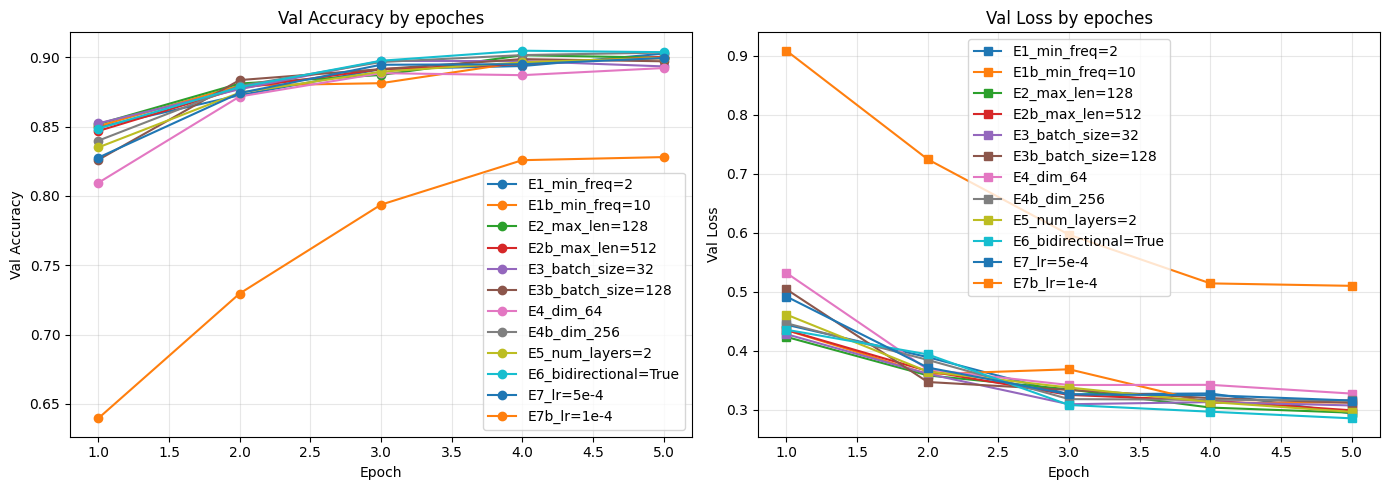

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for r in results:
    axes[0].plot(
        range(1, len(r['history']['val_acc']) + 1),
        r['history']['val_acc'],
        marker='o', label=r['name']
    )
    axes[1].plot(
        range(1, len(r['history']['val_loss']) + 1),
        r['history']['val_loss'],
        marker='s', label=r['name']
    )

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val Accuracy')
axes[0].set_title('Val Accuracy by epoches'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val Loss')
axes[1].set_title('Val Loss by epoches'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

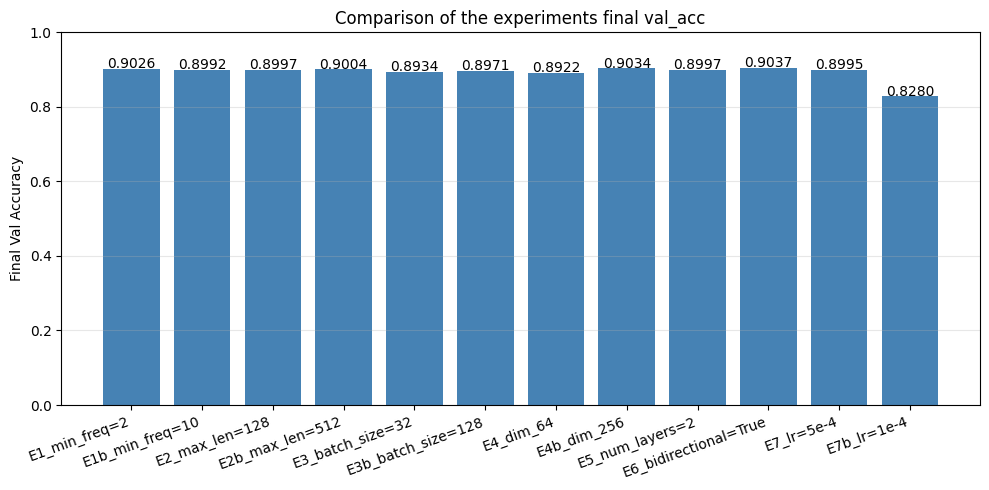

In [35]:
plt.figure(figsize=(10, 5))
bars = plt.bar(df['experiment'], df['final_val_acc'], color='steelblue')

for b, v in zip(bars, df['final_val_acc']):
    plt.text(b.get_x() + b.get_width()/2, v + 0.002,
             f"{v:.4f}", ha='center', fontsize=10)

plt.ylim(0, 1.0)
plt.ylabel('Final Val Accuracy')
plt.title('Comparison of the experiments final val_acc')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#Задание 2

In [36]:
class_names = ['World', 'Sports', 'Business', 'Sci/Tech']
# 0 → World, 1 → Sports, 2 → Business, 3 → Sci/Tech

from collections import Counter
print("Labels in test_data:", Counter(label for label, _ in test_data))

val_loss, val_acc, all_preds, all_labels = evaluate(
    model, test_loader, criterion, device
)
print(f"Test accuracy: {val_acc:.4f}")


errors = []
for i, (true_lbl, pred_lbl) in enumerate(zip(all_labels, all_preds)):
    if true_lbl != pred_lbl:
        _, text = test_data[i]
        errors.append({
            'true': int(true_lbl),
            'pred': int(pred_lbl),
            'text': text,
        })

print(f"Total errors: {len(errors)} из {len(test_data)}")

# первые 10
for n, e in enumerate(errors[:10], start=1):
    short = e['text'][:200].replace('\n', ' ')
    print(f"\n#{n}")
    print(f"  True class:      [{e['true']}] {class_names[e['true']]}")
    print(f"  Predicted class: [{e['pred']}] {class_names[e['pred']]}")
    print(f"  Text: {short}...")

Labels in test_data: Counter({2: 1900, 3: 1900, 1: 1900, 0: 1900})
Test accuracy: 0.9026
Total errors: 740 из 7600

#1
  True class:      [3] Sci/Tech
  Predicted class: [2] Business
  Text: IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991....

#2
  True class:      [3] Sci/Tech
  Predicted class: [2] Business
  Text: Some People Not Eligible to Get in on Google IPO Google has billed its IPO as a way for everyday people to get in on the process, denying Wall Street the usual stranglehold it's had on IPOs. Public bi...

#3
  True class:      [0] World
  Predicted class: [2] Business
  Text: Venezuela Prepares for Chavez Recall Vote Supporters and rivals warn of possible fraud; government says Chavez's defeat could produce turmoil in world oil market....

#4
  True class:      [3] Sci/Tech
  Predicted class: [1] Sports
  Text: Promoting a Shared Vision As Michael Kaleko kept running into people who were getting o

**3 типичные ошибки и идеи по их устранению**

**1. Business and Sci/Tech confusion** (примеры #1, #2, #6, #7) - в новостях tech-компаний корпоративная лексика (IPO, price cuts) перевешивает отраслевую (chip, Web hosting).
**Идея:** создать бинарный арбитр только для этой пары + делить на признаки tech-компания/продукт.

**2. World and Business confusion** (примеры #3, #8) - экономическая лексика (oil market, record high) перебивает геополитические маркеры (Venezuela, recall vote).
**Идея:** ввести фичу геополитической сущности (страна/политик/выборы) с повышенным весом, отдавать приоритет теме World при ее сильном сигнале.

**3. Sports and World / Sci/Tech confusion** (примеры #4, #5, #9) - география и цитаты в репортажах дают ложный World, а лексика по типу running/going for gold - ложный Sports.
→ **Идея:** список спортивных сущностей (Olympics, атлеты) как отдельный канал + штраф этого спортивного "скора" за медицинскую/продуктовую лексику в Sports.


#Задание 3

In [37]:
class LSTMClassifierV2(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        pad_idx,
        num_layers=1,
        dropout=0.2,
        bidirectional=False,
        rnn_type='LSTM'          # 'RNN' | 'LSTM' | 'GRU'
    ):
        super().__init__()

        self.rnn_type = rnn_type
        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=pad_idx
        )

        rnn_cls = {'LSTM': nn.LSTM}[rnn_type]

        self.rnn = rnn_cls(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = hidden_dim * 2 if bidirectional else hidden_dim

        self.fc = nn.Linear(rnn_output_dim, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))

        packed = pack_padded_sequence(
            embedded, lengths.cpu(),
            batch_first=True, enforce_sorted=False
        )

        output, hidden = self.rnn(packed)

        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        if self.bidirectional:
            last_hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            last_hidden = hidden[-1]

        return self.fc(self.dropout(last_hidden))

In [39]:
def run_experiment(
    name,
    train_data, test_data,
    min_freq=5, max_len=128, batch_size=64,
    embed_dim=128, hidden_dim=128,
    num_layers=2, bidirectional=True,
    dropout=0.2, learning_rate=1e-3,
    num_epochs=5, num_classes=4,
    rnn_type='RNN',
    seed=42, verbose=True
):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    vocab = build_vocab(train_data, min_freq=min_freq)
    train_loader, test_loader = make_dataloaders(
        train_data, test_data, vocab,
        max_len=max_len, batch_size=batch_size
    )

    model = LSTMClassifierV2(
        vocab_size=len(vocab),
        embed_dim=embed_dim, hidden_dim=hidden_dim,
        num_classes=num_classes, pad_idx=vocab['<pad>'],
        num_layers=num_layers, dropout=dropout,
        bidirectional=bidirectional, rnn_type=rnn_type
    ).to(device)

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    epoch_times = []

    for epoch in range(num_epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        ep_time = time.time() - t0
        va_loss, va_acc, _, _ = evaluate(model, test_loader, criterion, device)

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        epoch_times.append(ep_time)

        if verbose:
            print(f"[{name}] Ep {epoch+1}/{num_epochs} | "
                  f"TrLoss {tr_loss:.4f} TrAcc {tr_acc:.4f} | "
                  f"VaLoss {va_loss:.4f} VaAcc {va_acc:.4f} | {ep_time:.1f}s")

    return {
        'name': name, 'rnn_type': rnn_type,
        'num_layers': num_layers, 'bidirectional': bidirectional,
        'vocab_size': len(vocab), 'n_params': n_params,
        'avg_epoch_time': float(np.mean(epoch_times)),
        'final_val_loss': history['val_loss'][-1],
        'final_val_acc': history['val_acc'][-1],
        'history': history,
    }

In [40]:
EXPERIMENTS = [
    dict(name="C3_biLSTM_2L", rnn_type='LSTM', num_layers=2, bidirectional=True),
]

results = []
for exp in EXPERIMENTS:
    res = run_experiment(
        **exp,
        train_data=train_data, test_data=test_data,
        min_freq=5, max_len=128, batch_size=64,
        embed_dim=128, hidden_dim=128,
        dropout=0.2, learning_rate=1e-3,
        num_epochs=5, verbose=True
    )
    results.append(res)
    print("-" * 80)

[C3_biLSTM_2L] Ep 1/5 | TrLoss 0.4797 TrAcc 0.8224 | VaLoss 0.2960 VaAcc 0.8987 | 53.9s
[C3_biLSTM_2L] Ep 2/5 | TrLoss 0.2637 TrAcc 0.9092 | VaLoss 0.2488 VaAcc 0.9149 | 51.6s
[C3_biLSTM_2L] Ep 3/5 | TrLoss 0.2063 TrAcc 0.9284 | VaLoss 0.2358 VaAcc 0.9221 | 51.3s
[C3_biLSTM_2L] Ep 4/5 | TrLoss 0.1708 TrAcc 0.9402 | VaLoss 0.2290 VaAcc 0.9247 | 51.2s
[C3_biLSTM_2L] Ep 5/5 | TrLoss 0.1419 TrAcc 0.9499 | VaLoss 0.2375 VaAcc 0.9257 | 51.2s
--------------------------------------------------------------------------------


In [41]:
df_2 = pd.DataFrame([{
    'experiment':       r['name'],
    'rnn_type':         r['rnn_type'],
    'num_layers':       r['num_layers'],
    'bidirectional':    r['bidirectional'],
    'vocab_size':       r['vocab_size'],
    'n_params':         r['n_params'],
    'avg_epoch_time_s': round(r['avg_epoch_time'], 1),
    'final_val_loss':   round(r['final_val_loss'], 4),
    'final_val_acc':    round(r['final_val_acc'], 4),
} for r in results])

df_2

,experiment,rnn_type,num_layers,bidirectional,vocab_size,n_params,avg_epoch_time_s,final_val_loss,final_val_acc
0,C3_biLSTM_2L,LSTM,2,True,27831,4222852,51.9,0.2375,0.9257


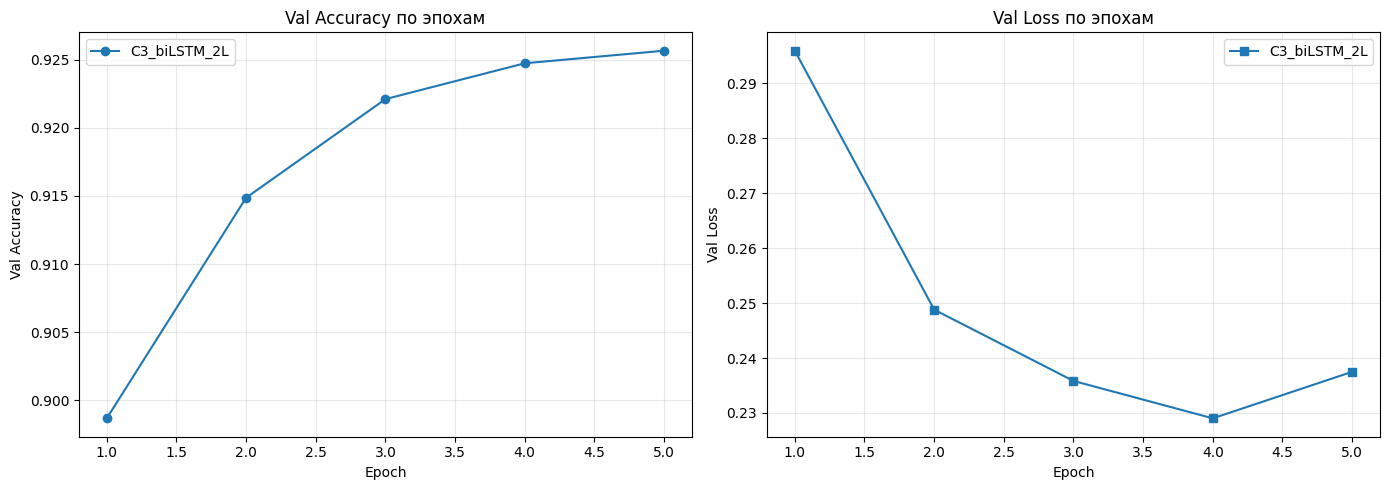

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for r in results:
    epochs = range(1, len(r['history']['val_acc']) + 1)
    axes[0].plot(epochs, r['history']['val_acc'], marker='o', label=r['name'])
    axes[1].plot(epochs, r['history']['val_loss'], marker='s', label=r['name'])

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val Accuracy')
axes[0].set_title('Val Accuracy по эпохам'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val Loss')
axes[1].set_title('Val Loss по эпохам'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

**Результат:** accuracy = 0.9257 (возросла по сравнению с 0.9037), loss  уменьшилась от 0.2857 до 0.2375, но на 4 эпохе обучения loss была меньше, чем на 5, несмотря на продолжение роста accuracy.

LSTM и GRU превосходят обычные RNN за счёт того, что их механизм памяти позволяет градиенту проходить через сотни шагов, не затухая экспоненциально. Благодаря обучению избирательно запоминать и забывать, модель может опираться на информацию по всему тексту, а не только на его последнюю часть.

#Задание 4

In [43]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model, test_loader, criterion, device
)
print(f"Test accuracy: {val_acc:.4f}")

#lengths
word_lengths = np.array([len(text.split()) for _, text in test_data])
correct = (np.array(all_preds) == np.array(all_labels)).astype(int)

# groups by length
bins   = [0, 50, 100, 200, 10_000]
labels = ['0–50', '51–100', '101–200', '200+']

group_ids = np.digitize(word_lengths, bins) - 1

rows = []
for gid, gname in enumerate(labels):
    mask = group_ids == gid
    n = int(mask.sum())
    acc = float(correct[mask].mean()) if n > 0 else float('nan')
    rows.append({'group': gname, 'n': n, 'accuracy': acc})

length_df = pd.DataFrame(rows)
print(length_df)

Test accuracy: 0.9026
     group     n  accuracy
0     0–50  6996  0.904803
1   51–100   586  0.877133
2  101–200    18  0.888889
3     200+     0       NaN


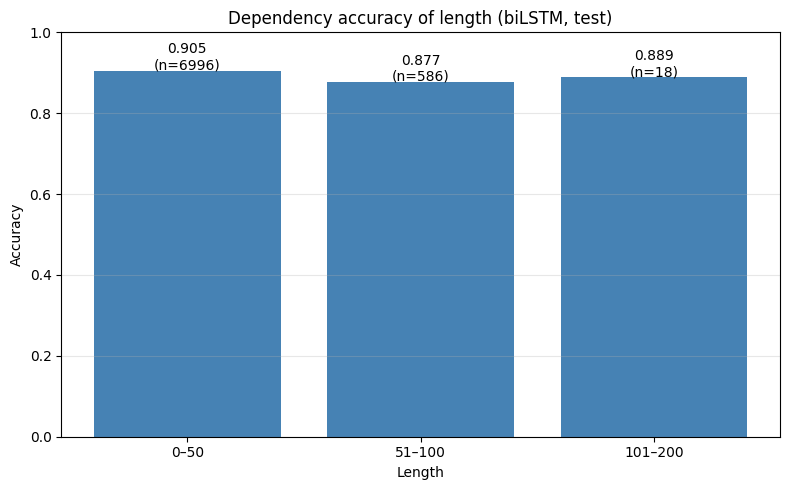

In [44]:
plt.figure(figsize=(8, 5))

bars = plt.bar(length_df['group'], length_df['accuracy'], color='steelblue')

for b, acc, n in zip(bars, length_df['accuracy'], length_df['n']):
    plt.text(b.get_x() + b.get_width()/2, acc + 0.003,
             f"{acc:.3f}\n(n={n})", ha='center', fontsize=10)

plt.ylim(0, 1.0)
plt.xlabel('Length')
plt.ylabel('Accuracy')
plt.title('Dependency accuracy of length (biLSTM, test)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
#accuracy for each group
for gid, gname in enumerate(labels):
    mask = group_ids == gid
    if mask.sum() == 0:
        continue
    print(f"{gname:>8}  n={mask.sum():>5}  acc={correct[mask].mean():.3f}")

    0–50  n= 6996  acc=0.905
  51–100  n=  586  acc=0.877
 101–200  n=   18  acc=0.889


Вывод: короткие тексты определяются точнее.